In [1]:
%load_ext autoreload
%autoreload 2

In [42]:

# %%
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import json
import os
from datetime import datetime
from pathlib import Path

# from dualwcfm.trainers.dual_trainer import DualTrainer, DualTrainerConfig
# from dualwcfm.visualization import plot_2d_flow_trajectories
# from dualwcfm.models.cfm import ConditionalFlowMatching
# from dualwcfm.trainers.dynamic_trainer import DynamicTrainer
# from dualwcfm.models.cfm import torch_wrapper
# from dualwcfm.trainers.wcfm import CFMTrainerConfig
from torchcfm.models.models import MLP
from dualwcfm.distributions.distribution import Distribution
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution
from dualwcfm.distributions import CouplingDistribution, RotatedShapeCoupling, Simple2DGaussianDistribution, RotatedDistribution, MoonDistribution
from dualwcfm.visualizer import plot_2d_flow_trajectories
from dualwcfm.cfm import ConditionalFlowMatching
from dualwcfm.distributions.distribution import Distribution, FixedSizeDistribution

# %%
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# %%
import torch
import torch.nn as nn
from torchdyn.core import NeuralODE

class LagrangianFlowField(nn.Module):
    """
    Wraps a velocity network to handle 'Source Conditioning'.
    State z = [x_t, x_0] (Dimension 2*D)
    Dynamics: dx/dt = net(x_t, x_0, t), dx_0/dt = 0
    """
    def __init__(self, net, dim):
        super().__init__()
        self.net = net
        self.dim = dim

    def forward(self, x):
        x_t = x[:, :self.dim]      # Current Position (Evolving)
        x_0 = x[:, self.dim:2*self.dim]      # Initial Position (Constant Context)

        v_x = self.net(x)
        v_c = torch.zeros_like(x_0)
        return torch.cat([v_x, v_c], dim=1)

import math

class SphereDistribution(Distribution):
    """Samples points uniformly inside a 3D sphere."""
    def __init__(self, mean: torch.Tensor, radius: float = 0.5):
        self.mean = mean
        self.radius = radius

    def sample(self, n: int) -> torch.Tensor:
        # Sample random directions
        phi = torch.rand(n) * 2 * math.pi
        costheta = torch.rand(n) * 2 - 1
        u = torch.rand(n)
        
        theta = torch.acos(costheta)
        r = self.radius * (u ** (1/3)) # Cube root for uniform volume sampling
        
        x = r * torch.sin(theta) * torch.cos(phi)
        y = r * torch.sin(theta) * torch.sin(phi)
        z = r * torch.cos(theta)
        
        return torch.stack([x, y, z], dim=-1) + self.mean

class ShiftedDistribution(Distribution):
    def __init__(self, base_distribution, shift):
        self.base_distribution = base_distribution
        self.shift = shift

    def sample(self, n):
        samples = self.base_distribution.sample(n)
        return samples + self.shift.to(samples.device)

In [53]:
def get_rotation_matrix():
    # Angle to tilt the cube so diagonal (1,1,1) is vertical
    alpha = math.pi / 4  # 45 degrees
    beta = math.acos(1.0 / math.sqrt(3.0)) # ~54.74 degrees
    
    # Rotation around Z
    Rz = torch.tensor([
        [math.cos(alpha), -math.sin(alpha), 0],
        [math.sin(alpha),  math.cos(alpha), 0],
        [0,                0,               1]
    ])
    
    # Rotation around Y
    Ry = torch.tensor([
        [math.cos(beta),  0, math.sin(beta)],
        [0,               1, 0             ],
        [-math.sin(beta), 0, math.cos(beta)]
    ])

    return Ry @ Rz

def anticorrelate(n: int):
    source_samples = torch.randn(n, 2) * 0.5
    return source_samples, -source_samples

def cube_coupling(n: int):
    cube_samples = 2*torch.rand(n, 3) - 1

    R = get_rotation_matrix()
    rotated_samples = cube_samples @ R.T

    translation = torch.tensor([-2.0, -2.0, -2.0])
    source_samples = rotated_samples + translation

    return source_samples, -source_samples

# Make a theta degree rotation function
def rotation_fun(x, theta):
    rotation_matrix = torch.tensor([
        [torch.cos(theta), -torch.sin(theta)],
        [torch.sin(theta),  torch.cos(theta)]
    ]).to(x.device)
    return x @ rotation_matrix.T

def create_distributions(device):
    """Create and return all distributions for the experiment."""
    coupling_dist = RotatedShapeCoupling(
        centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
        source_scale=0.2,
        target_scale=0.2,
        rotation_degrees=90.0,
        source_shift=(0.0, 0.0),
        target_shift=(0.0, 0.0),
        transformation=lambda x: torch.stack([-x[:,0], x[:,1]], dim=1),
        device=device
    )
    source_dist, target_dist = coupling_dist.get_marginals()
    new_source_dist = ShiftedDistribution(MoonDistribution(), shift=torch.tensor([6.0, 0.0]))
    new_target_dist = ShiftedDistribution(
        RotatedDistribution(new_source_dist, angle=torch.pi / 2, transformation=lambda x: torch.stack([-x[:,0], x[:,1]], dim=1),),
        shift=torch.tensor([0.0, 0.0])
    )


    # coupling_dist = FunctionalCouplingDistribution(anticorrelate)
    # source_dist, target_dist = coupling_dist.get_marginals()
    # new_source_dist = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 4.0]), std=torch.tensor([1.0, 1.0]))
    # new_target_dist = Simple2DGaussianDistribution(mean=torch.tensor([-4.0, -5.0]), std=torch.tensor([1.0, 1.0]))

    coupling_dist = FunctionalCouplingDistribution(cube_coupling)
    source_dist, target_dist = coupling_dist.get_marginals()
    new_source_dist = SphereDistribution(mean=torch.tensor([5.0, -5.0, 5.0]), radius=1.0)
    new_target_dist = SphereDistribution(mean=torch.tensor([-5.0, 5.0, -5.0]), radius=1.0)

    return {
        'coupling_dist': coupling_dist,
        'source_dist': source_dist,
        'target_dist': target_dist,
        'new_source_dist': new_source_dist,
        'new_target_dist': new_target_dist
    }

def plot_distributions(distributions, n_samples=2000, n_lines=25):
    """Visualize all distributions."""
    coupling_dist = distributions['coupling_dist']
    new_source_dist = distributions['new_source_dist']
    new_target_dist = distributions['new_target_dist']

    coupling_samples = coupling_dist.coupling_sample(n_samples)
    source_samples = coupling_samples[0].cpu().numpy()
    target_samples = coupling_samples[1].cpu().numpy()
    new_source_samples = new_source_dist.sample(n_samples).cpu().numpy()
    new_target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    fig = plt.figure(figsize=(8, 8))
    plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
    plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
    plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
    plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
    plt.plot([source_samples[:n_lines, 0], target_samples[:n_lines, 0]], [source_samples[:n_lines, 1], target_samples[:n_lines, 1]], c='purple', alpha=1.0, lw=0.6, label='Original Coupling')
    plt.title('Samples from Original and New Distributions')
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())
    plt.tight_layout()
    plt.show()

def plot_distributions_3d(distributions, n_samples=2000):
    """Visualize all distributions in 3D."""
    from mpl_toolkits.mplot3d import Axes3D  # Importing here to avoid unnecessary dependency if not used

    coupling_dist = distributions['coupling_dist']
    new_source_dist = distributions['new_source_dist']
    new_target_dist = distributions['new_target_dist']

    coupling_samples = coupling_dist.coupling_sample(n_samples)
    source_samples = coupling_samples[0].cpu().numpy()
    target_samples = coupling_samples[1].cpu().numpy()
    new_source_samples = new_source_dist.sample(n_samples).cpu().numpy()
    new_target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(source_samples[:, 0], source_samples[:, 1], source_samples[:, 2], c='orange', s=8, alpha=0.5, label='Original Source Samples')
    ax.scatter(target_samples[:, 0], target_samples[:, 1], target_samples[:, 2], c='grey', s=8, alpha=0.5, label='Original Target Samples')
    ax.scatter(new_source_samples[:, 0], new_source_samples[:, 1], new_source_samples[:, 2], c='blue', s=8, alpha=0.5, label='New Source Samples')
    ax.scatter(new_target_samples[:, 0], new_target_samples[:, 1], new_target_samples[:, 2], c='red', s=8, alpha=0.5, label='New Target Samples')
    ax.set_title('3D Samples from Original and New Distributions')
    # Plot coupling lines
    for i in range(25):
        ax.plot([source_samples[i, 0], target_samples[i, 0]],
                [source_samples[i, 1], target_samples[i, 1]],
                [source_samples[i, 2], target_samples[i, 2]],
                c='purple', alpha=1.0, lw=0.6)

    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys())
    plt.tight_layout()
    plt.show()

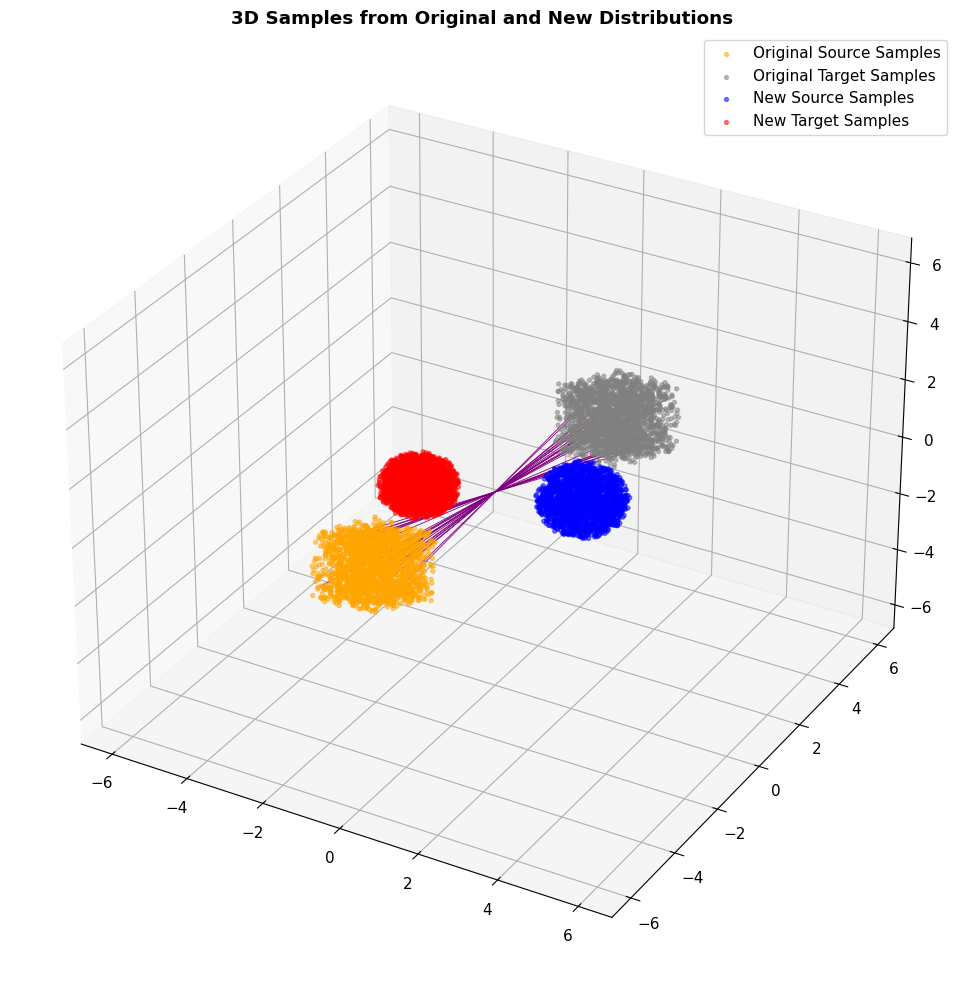

In [54]:
# plot_distributions(create_distributions(device), n_samples=2000, n_lines=100)
plot_distributions_3d(create_distributions(device), n_samples=2000)

In [45]:
def interpolate(x0, x1, s, sigma):
    return (1 - s) * x0 + s * x1 + sigma * torch.randn_like(x0) * torch.sqrt(s * (1 - s))


In [63]:
def plot_flow_trajectories(trajectories, t, n_trajectories, target_samples, title, xlim=None, ylim=None):
    if trajectories.shape[2] == 4:
        # plot_2d_flow_trajectories(
        #     trajectories=trajectories,
        #     t=time,
        #     n_trajectories=n_trajectories,
        #     target_points=target_samples,
        #     title=f"Final W-CFM Trajectories",
        # )
        fig, ax = plt.subplots(figsize=(8, 8))
        trajectories_np = trajectories.cpu().numpy()

        n_trajectories = min(n_trajectories, trajectories.shape[1])

        from matplotlib.collections import LineCollection

        segments = []
        for j in range(n_trajectories):
            points = trajectories_np[:, j, :2]
            segs = np.stack([points[:-1], points[1:]], axis=1)
            segments.extend(segs)

        start_points = trajectories_np[0, :, :2]
        end_points = trajectories_np[-1, :, :2]

        if target_samples is not None:
            ax.scatter(target_samples[:, 0], target_samples[:, 1], c="orange", s=5, alpha=0.5, zorder=4, label="Target")
        ax.scatter(start_points[:, 0], start_points[:, 1], c="red", s=5, alpha=0.5, zorder=4, label="Start")
        ax.scatter(end_points[:, 0], end_points[:, 1], c="green", s=5, alpha=0.5, zorder=4, label="End")
        mid_points = trajectories_np[trajectories_np.shape[0] // 2, :, :2]
        ax.scatter(mid_points[:, 0], mid_points[:, 1], c="blue", s=5, alpha=0.5, zorder=4, label="Mid")
        ax.grid(True, alpha=0.2)
        ax.set_title(title)

        lc = LineCollection(segments, colors="gray", alpha=0.5, linewidths=0.8, zorder=1)
        ax.add_collection(lc)

        if xlim is not None:
            ax.set_xlim(xlim)
        if ylim is not None:
            ax.set_ylim(ylim)

        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.legend()
    elif trajectories.shape[2] == 6:
        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(111, projection='3d')
        trajectories_np = trajectories.cpu().numpy()

        n_trajectories = min(n_trajectories, trajectories.shape[1])

        for j in range(n_trajectories):
            points = trajectories_np[:, j, :3]
            ax.plot(points[:, 0], points[:, 1], points[:, 2], c='gray', alpha=0.5)

        start_points = trajectories_np[0, :, :3]
        end_points = trajectories_np[-1, :, :3]

        if target_samples is not None:
            ax.scatter(target_samples[:, 0], target_samples[:, 1], target_samples[:, 2], c="orange", s=5, alpha=0.5, zorder=4, label="Target")
        ax.scatter(start_points[:, 0], start_points[:, 1], start_points[:, 2], c="red", s=5, alpha=0.5, zorder=4, label="Start")
        ax.scatter(end_points[:, 0], end_points[:, 1], end_points[:, 2], c="green", s=5, alpha=0.5, zorder=4, label="End")
        mid_points = trajectories_np[trajectories_np.shape[0] // 2, :, :3]
        ax.scatter(mid_points[:, 0], mid_points[:, 1], mid_points[:, 2], c="blue", s=5, alpha=0.5, zorder=4, label="Mid")
        ax.set_title(title)

        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.set_zlabel("Z")
        ax.legend()

In [64]:
class Experiment:
    """Encapsulates the entire training experiment with metrics and saving."""

    def __init__(self, name, config, coupling_fun=None, dim=2):
        self.switch_config(name, config)
        self.coupling_fun = coupling_fun if coupling_fun is not None else (lambda x: -x)
        self.dim = dim

    def switch_config(self, name, config):
        """Switch experiment configuration."""
        self.name = name
        self.config = config
        self.device = config.get("device", device)
        self.metrics = {
            "marginal_losses": {"mu": [], "nu": []},
            "dual_losses": [],
            "cfm_losses": {"mu": [], "nu": []},
            "coupling_errors": {"mse": [], "min": [], "max": []},
            "mass_conservation": [],
        }
        self.experiment_dir = None

    def setup_directories(self):
        """Create directories for saving experiment results."""
        self.experiment_dir = Path(f"experiments/{self.name}")
        self.experiment_dir.mkdir(parents=True, exist_ok=True)

        # Save config
        with open(self.experiment_dir / "config.json", "w") as f:
            json.dump(self.config, f, indent=2, default=str)

    def save_metrics(self):
        """Save metrics to file."""
        if self.experiment_dir:
            with open(self.experiment_dir / "metrics.json", "w") as f:
                json.dump(
                    self.metrics,
                    f,
                    indent=2,
                    default=lambda x: float(x) if isinstance(x, (torch.Tensor, np.generic)) else x,
                )

    def save_checkpoint(self, models, step):
        """Save model checkpoints."""
        if self.experiment_dir:
            checkpoint_dir = self.experiment_dir / "checkpoints"
            checkpoint_dir.mkdir(exist_ok=True)

            checkpoint = {
                "step": step,
                "models": {name: model.state_dict() for name, model in models.items()},
                "metrics": self.metrics,
            }
            torch.save(checkpoint, checkpoint_dir / f"checkpoint_step_{step}.pt")

            # Save latest
            torch.save(checkpoint, checkpoint_dir / "latest.pt")

    def plot_iteration_diagnostics(self, step, x_ref, y_ref, f_net, g_net, flow_model, device):
        """Visualizes the coupling, the learned weights, and the vector field."""
        x_ref_np = x_ref.detach().cpu().numpy()
        y_ref_np = y_ref.detach().cpu().numpy()
        with torch.no_grad():
            a = f_net(x_ref).view(-1)
            b = g_net(y_ref).view(-1)
            log_weights = a + b

        # Grid for vector field
        grid_n = 20
        x = np.linspace(-10, 10, grid_n)
        y = np.linspace(-10, 10, grid_n)
        X, Y = np.meshgrid(x, y)
        grid = torch.tensor(np.stack([X.flatten(), Y.flatten()], axis=1), dtype=torch.float32).to(device)

        # Flow Vector Field (at t=0 for this step)
        t_zeros = torch.zeros(grid.shape[0], 1).to(device)
        with torch.no_grad():
            vectors = flow_model(torch.cat([grid, grid, t_zeros], dim=1)).cpu().numpy()
            # vectors = flow_model(torch.cat([grid, torch.randn_like(grid), t_zeros], dim=1)).cpu().numpy()
        U = vectors[:, 0].reshape(grid_n, grid_n)
        V = vectors[:, 1].reshape(grid_n, grid_n)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        sc = axes[0].scatter(
            x_ref_np[:, 0], x_ref_np[:, 1], c=log_weights.cpu().numpy(), cmap="viridis", s=5, alpha=0.6
        )
        axes[0].set_title(f"Step {step}: Source Samples\n(Color = Log Learned Weight)")
        plt.colorbar(sc, ax=axes[0])
        axes[0].set_xlim(-10, 10)
        axes[0].set_ylim(-10, 10)

        axes[1].scatter(
            y_ref_np[:, 0], y_ref_np[:, 1], c=log_weights.cpu().numpy(), s=5, alpha=0.3, label="Target Coupling Y"
        )
        axes[1].set_title(f"Step {step}: Target Samples")
        axes[1].set_xlim(-10, 10)
        axes[1].set_ylim(-10, 10)

        axes[2].quiver(X, Y, U, V, color="blue", alpha=0.8)
        axes[2].set_title(f"Step {step}: Learned Flow Field (v_t)")
        axes[2].set_xlim(-10, 10)
        axes[2].set_ylim(-10, 10)

        plt.tight_layout()

        if self.experiment_dir:
            plt.savefig(self.experiment_dir / f"diagnostics_step_{step}.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

    def evaluate_coupling(self, x, y):
        """
        Evaluate the quality of generated coupling.
        For the anticorrelate function, ideal coupling should have y = -x.
        Returns various metrics.
        """
        with torch.no_grad():
            # MSE between y and -x (ideal coupling)
            mse = torch.mean((y - self.coupling_fun(x)) ** 2).item()

            # L1 distance
            l1 = torch.mean(torch.abs(y - self.coupling_fun(x))).item()

            # Max error
            max_err = torch.max((y - self.coupling_fun(x)) ** 2).item()

            # Correlation (should be -1 for perfect anticorrelation)
            corr = torch.corrcoef(torch.stack([x.flatten(), y.flatten()]))[0, 1].item()

        return {"mse": mse, "l1": l1, "max_error": max_err, "correlation": corr}

    def print_mass_conservation_check(self, x, y, f_net, g_net, delta):
        """
        Checks if the learned potentials a(x) and b(y) naturally conserve mass.
        The goal is for the Net Mass Flux to be 0 (Mean Weight - 1 = 0).
        """
        with torch.no_grad():
            a = f_net(x)
            b = g_net(y)

            raw_log_w = (a + b) * delta
            raw_w = torch.exp(raw_log_w)
            mass_flux_error = raw_w.mean() - 1.0

            self.metrics["mass_conservation"].append(
                {
                    "mean_weight": raw_w.mean().item(),
                    "mass_flux_error": mass_flux_error.item(),
                    "step": len(self.metrics["mass_conservation"]),
                }
            )

        print(f"--- Mass Conservation Check ---")
        print(f"Mean Weight:       {raw_w.mean().item():.5f} (Target: 1.0)")
        print(f"Net Mass Flux:     {mass_flux_error.item():.5f} (Target: 0.0)")

    def train_marginal_cfm(self, distributions):
        """Train marginal conditional flow matching models."""
        print("Training marginal CFM...")

        flow_mu = MLP(dim=self.dim, out_dim=self.dim, w=64, time_varying=True).to(self.device)
        flow_nu = MLP(dim=self.dim, out_dim=self.dim, w=64, time_varying=True).to(self.device)

        optimizer_mu = optim.Adam(flow_mu.parameters(), lr=1e-3)
        optimizer_nu = optim.Adam(flow_nu.parameters(), lr=1e-3)
        loss_fn = nn.MSELoss()

        batch_size = self.config.get("batch_size", 2048)
        epochs_marginal = self.config.get("epochs_marginal", 2500)
        sigma = self.config.get("sigma", 0.1)

        def interpolate(x0, x1, t, sigma):
            return (1 - t) * x0 + t * x1 + sigma * torch.randn_like(x0) * torch.sqrt(t * (1 - t))

        pbar = trange(epochs_marginal, desc="Training Marginal Bridges")
        for epoch in pbar:
            x0, y0 = distributions["coupling_dist"].coupling_sample(batch_size)
            x1, y1 = distributions["new_source_dist"].sample(batch_size), distributions["new_target_dist"].sample(
                batch_size
            )
            x0, x1, y0, y1 = x0.to(self.device), x1.to(self.device), y0.to(self.device), y1.to(self.device)

            t = torch.rand(batch_size, 1).to(self.device)
            xt, yt = interpolate(x0, x1, t, sigma), interpolate(y0, y1, t, sigma)

            u_t, v_t = flow_mu(torch.cat([xt, t], dim=1)), flow_nu(torch.cat([yt, t], dim=1))
            target_u_t, target_v_t = x1 - x0, y1 - y0

            optimizer_mu.zero_grad()
            optimizer_nu.zero_grad()

            loss_mu = loss_fn(u_t, target_u_t)
            loss_mu.backward()
            optimizer_mu.step()

            loss_nu = loss_fn(v_t, target_v_t)
            loss_nu.backward()
            optimizer_nu.step()

            # Record metrics
            self.metrics["marginal_losses"]["mu"].append(loss_mu.item())
            self.metrics["marginal_losses"]["nu"].append(loss_nu.item())

            pbar.set_postfix({"Loss mu": loss_mu.item(), "Loss nu": loss_nu.item()})

        cfm_mu = ConditionalFlowMatching(
            distributions["source_dist"], distributions["new_source_dist"], flow_mu, sigma=sigma
        )
        cfm_nu = ConditionalFlowMatching(
            distributions["target_dist"], distributions["new_target_dist"], flow_nu, sigma=sigma
        )

        return cfm_mu, cfm_nu, flow_mu, flow_nu

    def run(self, retrain=True):
        """Main training loop."""
        print("Setting up experiment...")
        self.setup_directories()

        print(self.config)

        # Create distributions
        distributions = create_distributions(self.device)

        # Plot initial distributions
        if self.dim == 2:
            plot_distributions(distributions)
        elif self.dim == 3:
            plot_distributions_3d(distributions)

        if retrain:
            # Train marginal CFM
            cfm_mu, cfm_nu, flow_mu, flow_nu = self.train_marginal_cfm(distributions)
            self.cfm_mu, self.cfm_nu, self.flow_mu, self.flow_nu = cfm_mu, cfm_nu, flow_mu, flow_nu
        else:
            cfm_mu, cfm_nu, flow_mu, flow_nu = self.cfm_mu, self.cfm_nu, self.flow_mu, self.flow_nu

        # Visualize marginal CFM trajectories
        n_samples = 2500
        n_timesteps = 50
        time = torch.linspace(0, 1, n_timesteps)

        traj_mu = cfm_mu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
        traj_nu = cfm_nu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
        target_mu_samples = distributions["new_source_dist"].sample(n_samples).cpu().numpy()
        target_nu_samples = distributions["new_target_dist"].sample(n_samples).cpu().numpy()

        plot_flow_trajectories(
            trajectories=traj_mu,
            t=time,
            n_trajectories=n_samples,
            target_samples=target_mu_samples,
            title=f"Flow Matching Trajectories for mu -> mu'",
        )
        plt.show()
        plot_flow_trajectories(
            trajectories=traj_nu,
            t=time,
            n_trajectories=n_samples,
            target_samples=target_nu_samples,
            title=f"Flow Matching Trajectories for nu -> nu'",
        )
        plt.show()

        # Main training parameters
        n_iterations = self.config.get("n_iterations", 100)
        epochs_dual_per_step = self.config.get("epochs_dual_per_step", 100)
        epochs_cfm_per_step = self.config.get("epochs_cfm_per_step", 250)
        delta = 1.0 / n_iterations
        dataset_size = self.config.get("dataset_size", 200_000)
        batch_size = self.config.get("batch_size", 2048)
        mode = self.config.get("mode", "implicit")
        sigma = self.config.get("sigma", 0.1)

        # Setup coupling distribution
        current_coupling_dist = FixedSizeCouplingDistribution(distributions["coupling_dist"], size=dataset_size)
        current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu()

        # Initialize networks
        f_net = MLP(dim=self.dim, out_dim=1, w=16, time_varying=False).to(self.device)
        g_net = MLP(dim=self.dim, out_dim=1, w=16, time_varying=False).to(self.device)
        flow_model_mu = MLP(dim=2*self.dim, out_dim=2*self.dim, w=16, time_varying=True).to(self.device)
        flow_model_nu = MLP(dim=2*self.dim, out_dim=2*self.dim, w=16, time_varying=True).to(self.device)
        previous_flow_model_mu = MLP(dim=2*self.dim, out_dim=2*self.dim, w=16, time_varying=True)
        previous_flow_model_nu = MLP(dim=2*self.dim, out_dim=2*self.dim, w=16, time_varying=True)
        if retrain:
            self.initial_flow_model_mu = MLP(dim=2*self.dim, out_dim=2*self.dim, w=16, time_varying=True).to(self.device)
            self.initial_flow_model_nu = MLP(dim=2*self.dim, out_dim=2*self.dim, w=16, time_varying=True).to(self.device)

        # Optimizers
        optimizer_dual = optim.Adam(
            list(f_net.parameters()) + list(g_net.parameters()), lr=self.config.get("dual_lr", 1e-4)
        )
        cfm_optimizer_mu = optim.Adam(flow_model_mu.parameters(), lr=self.config.get("cfm_lr", 5e-3))
        cfm_optimizer_nu = optim.Adam(flow_model_nu.parameters(), lr=self.config.get("cfm_lr", 5e-3))

        # Initialize marginal distributions
        mu_dist, nu_dist = current_coupling_dist.get_marginals()
        mu_dist = FixedSizeDistribution(mu_dist, size=dataset_size)
        nu_dist = FixedSizeDistribution(nu_dist, size=dataset_size)

        flow_model_mu.to(device)
        flow_model_nu.to(device)

        if retrain:
            pbar = trange(self.config.get("pretrained_epochs", 10000), desc="Pretraining CFM Models")
            for _ in pbar:
                x0, x1 = current_coupling_dist.coupling_sample(batch_size)
                x0, x1 = x0.to(device), x1.to(device)

                s = torch.rand(batch_size, 1).to(device)
                xs_mu = interpolate(x0, x1, s, sigma)
                xs_nu = interpolate(x1, x0, s, sigma)

                u_s_mu = flow_model_mu(torch.cat([xs_mu, x0, s], dim=1))
                u_s_nu = flow_model_nu(torch.cat([xs_nu, x1, s], dim=1))

                target_mu = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)
                target_nu = torch.cat([x0 - x1, torch.zeros_like(x0)], dim=1)
                loss_mu = ((u_s_mu - target_mu)**2).mean()
                loss_nu = ((u_s_nu - target_nu)**2).mean()

                cfm_optimizer_mu.zero_grad()
                loss_mu.backward()
                cfm_optimizer_mu.step()
                cfm_optimizer_nu.zero_grad()
                loss_nu.backward()
                cfm_optimizer_nu.step()
                pbar.set_postfix({"CFM Loss mu": loss_mu.item(), "CFM Loss nu": loss_nu.item()})

            self.initial_flow_model_mu.load_state_dict(flow_model_mu.state_dict())
            self.initial_flow_model_nu.load_state_dict(flow_model_nu.state_dict())
        else:
            flow_model_mu.load_state_dict(self.initial_flow_model_mu.state_dict())
            flow_model_nu.load_state_dict(self.initial_flow_model_nu.state_dict())

        # Plot initial CFM trajectories
        cfm_pi = ConditionalFlowMatching(distributions["coupling_dist"].get_marginals()[0], distributions["new_source_dist"], flow_model_mu,sigma=0,)
        init_mu_samples = distributions["source_dist"].sample(n_samples).to(self.device)
        init_mu_samples = torch.cat([init_mu_samples, init_mu_samples], dim=1)
        traj_mu = cfm_pi.get_trajectory(x0=init_mu_samples, n_timesteps=n_timesteps)
        target_mu_samples = distributions["target_dist"].sample(n_samples).cpu().numpy()

        print("Plotting initial flow matching trajectories...")
        plot_flow_trajectories(
            trajectories=traj_mu,
            t=time,
            n_trajectories=n_samples,
            target_samples=target_mu_samples,
            title=f"Initial Flow Matching Trajectories for mu -> nu",
        )
        plt.show()

        # Divide by 10 the learning rates after pretraining
        for param_group in cfm_optimizer_mu.param_groups:
            param_group['lr'] /= 10
        for param_group in cfm_optimizer_nu.param_groups:
            param_group['lr'] /= 10

        # Training loop
        for step in range(n_iterations):
            t_current = step * delta
            t = torch.full((batch_size, 1), t_current).to(self.device)

            # Load previous models
            previous_flow_model_mu.load_state_dict(flow_model_mu.state_dict())
            previous_flow_model_nu.load_state_dict(flow_model_nu.state_dict())
            previous_flow_model_mu.to(self.device)
            previous_flow_model_nu.to(self.device)
            previous_flow_model_mu.eval()
            previous_flow_model_nu.eval()

            # Dual training
            f_net.train()
            g_net.train()

            pbar = trange(epochs_dual_per_step, desc=f"Dual Training Step {step}")
            for _ in pbar:
                x, y = current_coupling_dist.coupling_sample(batch_size)
                x_mu, y_nu = mu_dist.sample(batch_size).to(self.device), nu_dist.sample(batch_size).to(self.device)
                x, y = x.to(self.device), y.to(self.device)

                with torch.no_grad():
                    u_t = flow_mu(torch.cat([x_mu, t], dim=1))
                    v_t = flow_nu(torch.cat([y_nu, t], dim=1))

                x.requires_grad_(True)
                y.requires_grad_(True)
                x_mu.requires_grad_(True)
                y_nu.requires_grad_(True)

                a = f_net(x)
                b = g_net(y)
                a_mu = f_net(x_mu)
                b_nu = g_net(y_nu)

                # Loss computation
                term_coupling = torch.mean((a - a.mean() + b - b.mean()) ** 2)

                grad_a = torch.autograd.grad(a_mu.sum(), x_mu, create_graph=True, retain_graph=True, only_inputs=True)[
                    0
                ]
                grad_b = torch.autograd.grad(b_nu.sum(), y_nu, create_graph=True, retain_graph=True, only_inputs=True)[
                    0
                ]

                term_flow_a = torch.mean(torch.sum(grad_a * u_t, dim=1))
                term_flow_b = torch.mean(torch.sum(grad_b * v_t, dim=1))

                term_reg = 1e-3 * (torch.mean(a**2) + torch.mean(b**2)) + 1e-3 * (
                    torch.mean(a_mu**2) + torch.mean(b_nu**2)
                )

                gp_lambda = self.config.get("gp_lambda", 0.1)
                gp_f = ((grad_a.norm(2, dim=1) - 1) ** 2).mean()
                gp_g = ((grad_b.norm(2, dim=1) - 1) ** 2).mean()

                loss = 0.5 * term_coupling - term_flow_a - term_flow_b + term_reg + gp_lambda * (gp_f + gp_g)

                optimizer_dual.zero_grad()
                loss.backward()
                optimizer_dual.step()

                self.metrics["dual_losses"].append(loss.item())
                pbar.set_description(f"Dual Loss: {loss.item():.4f}")

            # CFM training
            flow_model_mu.train()
            flow_model_nu.train()
            f_net.eval()
            g_net.eval()

            pbar = trange(epochs_cfm_per_step, desc=f"CFM Training Step {step}")
            for epoch in pbar:
                x0, x1 = current_coupling_dist.coupling_sample(batch_size)
                x0, x1 = x0.to(self.device), x1.to(self.device)

                s = torch.rand(batch_size, 1).to(self.device)

                if step % 2 == 0:
                    xs = interpolate(x0, x1, s, sigma)
                    u_s_full = flow_model_mu(torch.cat([xs, x0, s], dim=1))
                    u_s = u_s_full[:, :self.dim]
                else:
                    xs = interpolate(x1, x0, s, sigma)
                    u_s_full = flow_model_nu(torch.cat([xs, x1, s], dim=1))
                    u_s = u_s_full[:, :self.dim]
                with torch.no_grad():
                    a, b = f_net(x0), g_net(x1)
                    r = a + b
                    log_w = r * delta
                    weight = torch.exp(log_w)

                if mode == "weight":
                    # Normalize weights
                    target_u_s = (x1 - x0) if step % 2 == 0 else (x0 - x1)
                    target_u_s = torch.cat([target_u_s, torch.zeros_like(x0)], dim=1)
                    loss = (weight * (u_s_full - target_u_s) ** 2).mean() / weight.mean()
                elif mode == "explicit":
                    with torch.no_grad():
                        if step % 2 == 0:
                            b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1)).detach()[:, :self.dim]
                            residual = (x1 - x0) * r - b_ta * r
                        else:
                            b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1)).detach()[:, :self.dim]
                            residual = (x0 - x1) * r - b_ta * r
                        schrodinger_target = b_ta + delta * residual
                        full_target = torch.cat([schrodinger_target, torch.zeros_like(x0)], dim=1)
                    loss = nn.functional.mse_loss(u_s_full, full_target)
                elif mode == "implicit":
                    with torch.no_grad():
                        b_hat_detached = u_s.detach()
                        if step % 2 == 0:
                            b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1))[:, :self.dim]
                            target = x1 - x0
                        else:
                            b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1))[:, :self.dim]
                            target = x0 - x1

                        itm_target = b_ta + (weight - 1.0) * (target - b_hat_detached)
                        full_target = torch.cat([itm_target, torch.zeros_like(x0)], dim=1)

                    loss = nn.functional.mse_loss(u_s_full, full_target)

                cfm_optimizer_mu.zero_grad()
                cfm_optimizer_nu.zero_grad()
                loss.backward()
                cfm_optimizer_mu.step()
                cfm_optimizer_nu.step()

                # Record CFM losses
                if step % 2 == 0:
                    self.metrics["cfm_losses"]["mu"].append(loss.item())
                else:
                    self.metrics["cfm_losses"]["nu"].append(loss.item())

                pbar.set_description(f"CFM Loss: {loss.item():.4f}")

            chunks = 100_000
            num_steps = 50
            dt = 1.0 / num_steps
            flow_mu.eval()
            flow_nu.eval()
            # cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
            cfm_mu = ConditionalFlowMatching(
                distributions["new_source_dist"], distributions["new_target_dist"], flow_model_mu, sigma=0
            )
            cfm_nu = ConditionalFlowMatching(
                distributions["new_target_dist"], distributions["new_source_dist"], flow_model_nu, sigma=0
            )
            with torch.no_grad():
                for i in trange(0, dataset_size, chunks):
                    samples = current_coupling_dist.dataset[:, i:i+chunks]
                    # x, y = samples[0].to(device), samples[1].to(device)
                    x_mu, y_nu = mu_dist.dataset[i:i+chunks].to(device), nu_dist.dataset[i:i+chunks].to(device)

                    t_tensor = torch.full((x_mu.shape[0], 1), t_current).to(device)

                    x_mu_next = x_mu.detach() + delta * flow_mu(torch.cat([x_mu, t_tensor], dim=1))
                    y_nu_next = y_nu.detach() + delta * flow_nu(torch.cat([y_nu, t_tensor], dim=1))

                    if step % 2 == 0:
                        # x_next = x.detach() + delta * flow_mu(torch.cat([x, t_tensor], dim=1))
                        x_next = x_mu_next.detach().clone()

                        xt = x_next.clone()
                        for j in range(num_steps):
                            t = torch.ones(x_next.shape[0], 1).to(device) * (j * dt)
                            vt = flow_model_mu(torch.cat([xt, x_next, t], dim=1))[:, :self.dim]
                            xt = xt + vt * dt
                        y_next = xt.clone()
                    else:
                        # y_next = y.detach() + delta * flow_nu(torch.cat([y, t_tensor], dim=1))
                        y_next = y_nu_next.detach().clone()

                        yt = y_next.clone()
                        for j in range(num_steps):
                            t = torch.ones(y_next.shape[0], 1).to(device) * (j * dt)
                            vt = flow_model_nu(torch.cat([yt, y_next, t], dim=1))[:, :self.dim]
                            yt = yt + vt * dt
                        x_next = yt.clone()

                    x_next = x_next.detach().cpu()
                    y_next = y_next.detach().cpu()

                    current_coupling_dist.dataset[:, i:i+chunks] = torch.stack([x_next, y_next], dim=0)
                    mu_dist.dataset[i:i+chunks] = x_mu_next.detach().cpu()
                    nu_dist.dataset[i:i+chunks] = y_nu_next.detach().cpu()


            # Evaluation and visualization
            if step % 25 == 0 or step == n_iterations - 1:
                x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
                x_ref, y_ref = x_ref.to(self.device), y_ref.to(self.device)

                # Plot diagnostics
                # self.plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model_mu, self.device)

                # Evaluate coupling
                coupling_metrics = self.evaluate_coupling(x_ref, y_ref)
                print(
                    f"Step {step}: Coupling Evaluation - MSE: {coupling_metrics['mse']:.4f}, "
                    f"L1: {coupling_metrics['l1']:.4f}, Corr: {coupling_metrics['correlation']:.4f}"
                )

                # Record coupling errors
                self.metrics["coupling_errors"]["mse"].append(coupling_metrics["mse"])
                self.metrics["coupling_errors"]["min"].append(coupling_metrics["l1"])  # Using L1 as min proxy
                self.metrics["coupling_errors"]["max"].append(coupling_metrics["max_error"])

                # Mass conservation check
                self.print_mass_conservation_check(x_ref, y_ref, f_net, g_net, delta)

                # Save checkpoint
                models = {
                    "f_net": f_net,
                    "g_net": g_net,
                    "flow_model_mu": flow_model_mu,
                    "flow_model_nu": flow_model_nu,
                    "flow_mu": flow_mu,
                    "flow_nu": flow_nu,
                }
                self.save_checkpoint(models, step)

                # Save metrics
                self.save_metrics()

        print("Training completed!")

        # Final visualization and metrics
        self.final_evaluation(distributions, f_net, g_net, flow_model_mu, flow_model_nu, current_coupling_dist)

        return {
            "models": {
                "f_net": f_net,
                "g_net": g_net,
                "flow_model_mu": flow_model_mu,
                "flow_model_nu": flow_model_nu,
                "flow_mu": flow_mu,
                "flow_nu": flow_nu,
            },
            "metrics": self.metrics,
            "experiment_dir": self.experiment_dir,
        }

    def final_evaluation(self, distributions, f_net, g_net, flow_model_mu, flow_model_nu, current_coupling_dist):
        """Final evaluation and visualization after training."""
        print("Performing final evaluation...")

        # Final coupling evaluation
        x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
        x_ref, y_ref = x_ref.to(self.device), y_ref.to(self.device)

        # self.plot_iteration_diagnostics(
        #     len(self.metrics["coupling_errors"]["mse"]),
        #     x_ref,
        #     y_ref,
        #     f_net,
        #     g_net,
        #     flow_model_mu,
        #     self.device,
        # )

        # Visualize learned W-CFM
        flow_model_mu.eval()
        with torch.no_grad():
            cfm = ConditionalFlowMatching(
                distributions["new_source_dist"], distributions["new_target_dist"], flow_model_mu, sigma=0
            )
            n_samples = 500
            n_timesteps = 50
            time = torch.linspace(0, 1, n_timesteps)
            x_init = distributions["new_source_dist"].sample(n_samples).to(self.device)
            x_init_extended = torch.cat([x_init, x_init], dim=1)
            traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
            target_samples = distributions["new_target_dist"].sample(n_samples).cpu().numpy()

            print("Plotting final W-CFM trajectories...", traj.shape[2])
            plot_flow_trajectories(
                trajectories=traj,
                t=time,
                n_trajectories=n_samples,
                target_samples=target_samples,
                title=f"Final W-CFM Trajectories",
            )
            plt.show()

        # Plot training curves
        self.plot_training_curves()
        plt.show()

    def plot_training_curves(self):
        """Plot training loss curves."""
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        # Marginal losses
        axes[0, 0].plot(self.metrics["marginal_losses"]["mu"], label="mu", alpha=0.7)
        axes[0, 0].plot(self.metrics["marginal_losses"]["nu"], label="nu", alpha=0.7)
        axes[0, 0].set_title("Marginal CFM Losses")
        axes[0, 0].set_xlabel("Epoch")
        axes[0, 0].set_ylabel("Loss")
        axes[0, 0].legend()
        axes[0, 0].grid(True, alpha=0.3)

        # Dual losses
        axes[0, 1].plot(self.metrics["dual_losses"], label="Dual Loss", color="green", alpha=0.7)
        axes[0, 1].set_title("Dual Training Loss")
        axes[0, 1].set_xlabel("Iteration")
        axes[0, 1].set_ylabel("Loss")
        axes[0, 1].grid(True, alpha=0.3)

        # CFM losses
        axes[1, 0].plot(self.metrics["cfm_losses"]["mu"], label="mu", alpha=0.7)
        axes[1, 0].plot(self.metrics["cfm_losses"]["nu"], label="nu", alpha=0.7)
        axes[1, 0].set_title("CFM Losses")
        axes[1, 0].set_xlabel("Iteration")
        axes[1, 0].set_ylabel("Loss")
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)

        # Coupling errors
        axes[1, 1].plot(self.metrics["coupling_errors"]["mse"], label="MSE", alpha=0.7)
        axes[1, 1].plot(self.metrics["coupling_errors"]["min"], label="Min Error", alpha=0.7)
        axes[1, 1].plot(self.metrics["coupling_errors"]["max"], label="Max Error", alpha=0.7)
        axes[1, 1].set_title("Coupling Errors")
        axes[1, 1].set_xlabel("Evaluation Step")
        axes[1, 1].set_ylabel("Error")
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()

        if self.experiment_dir:
            plt.savefig(self.experiment_dir / "training_curves.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

In [65]:
# Optional: Load and analyze saved experiment
def load_experiment(experiment_dir):
    """Load a saved experiment."""
    experiment_dir = Path(experiment_dir)

    # Load config
    with open(experiment_dir / "config.json", "r") as f:
        config = json.load(f)

    # Load metrics
    with open(experiment_dir / "metrics.json", "r") as f:
        metrics = json.load(f)

    # Load latest checkpoint
    checkpoint = torch.load(experiment_dir / "checkpoints" / "latest.pt")

    return {"config": config, "metrics": metrics, "checkpoint": checkpoint}


# Example usage:
# saved_experiment = load_experiment("experiments/experiment_20240101_120000")

In [ ]:
"""Main function to run the experiment."""
config_dummy = {
    "device": device,
    "batch_size": 2048,
    "epochs_marginal": 2500,
    "sigma": 0.1,
    "n_iterations": 100,
    "pretrained_epochs": 10000,
    "epochs_dual_per_step": 100,
    "epochs_cfm_per_step": 250,
    "dataset_size": 200_000,
    "mode": "implicit",
    "dual_lr": 1e-4,
    "cfm_lr": 5e-3,
    "gp_lambda": 0.1,
    "tau": 0.05,
}
# Experiment for all three modes and iteration being [10, 25, 50, 100, 200]:
iteration_settings = [10, 25, 50, 100, 200]
modes = ['weight', 'explicit', 'implicit']
# results_all = {}
from functools import partial
# coupling_fun = lambda x: -x  # Anticorrelate
# T((x, y)) = (1-x, -1-y)
# coupling_fun = lambda x: torch.stack([1 - x[:, 0], -1 - x[:, 1]], dim=1)
distributions = create_distributions(device)
def coupling_fun(x):
    device = x.device
    # return distributions["coupling_dist"].transform_source(x)
    R = get_rotation_matrix().to(device)
    rotated_samples = x @ R.T

    translation = torch.tensor([-2.0, -2.0, -2.0]).to(device)
    source_samples = rotated_samples + translation
    return -source_samples

experiment = Experiment(None, config_dummy, coupling_fun=coupling_fun, dim=3)#partial(rotation_fun, theta=torch.tensor(math.pi / 2)))
# results_rotation = {}
results_farantrot = {}
i = 0
for mode in modes:
    for n_iter in iteration_settings:
        config = {
            "device": device,
            "batch_size": 2048,
            "epochs_marginal": 30000,
            "sigma": 0.1,
            "n_iterations": n_iter,
            "pretrained_epochs": 30000,
            "epochs_dual_per_step": 100,
            "epochs_cfm_per_step": 250,
            "dataset_size": 200_000,
            "mode": mode,
            "dual_lr": 1e-4,
            "cfm_lr": 5e-3,
            "gp_lambda": 0.1,
            "tau": 0.05,
        }
        name = f"3d_{mode}_iter_{n_iter}_dual_{config['epochs_dual_per_step']}_cfm_{config['epochs_cfm_per_step']}"
        experiment.switch_config(name, config)
        results = experiment.run(retrain=(i==0))
        results_farantrot[f"{mode}_iter_{n_iter}"] = results
        i += 1

# print(f"Experiment saved to: {results['experiment_dir']}")



In [ ]:
# Load all experiments starting with 'gaussian_off_' and compute the mse using the function T((x, y) = (1-x, -1-y)
# coupling function (x1, x2) -> (1-x1, -1-x2)
coupling_fun = lambda x: torch.stack([1 - x[:, 0], -x[:, 1]], dim=1)
mses = {}
iteration_settings = [10, 25, 50, 100, 200]
modes = ['weight', 'explicit', 'implicit']
for mode in modes:
    for n_iter in iteration_settings:
        experiment_name = f"gaussian_off_{mode}_iter_{n_iter}_dual_100_cfm_250"
        try:
            experiment_path = Path("experiments") / experiment_name
            loaded_exp = load_experiment(experiment_path)
            checkpoint = loaded_exp["checkpoint"]
            distributions = create_distributions(device)
            source_dist = distributions['new_source_dist']
            target_dist = distributions['new_target_dist']
            flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(device)
            print(flow_model_mu.net[0].weight)
            flow_model_mu.load_state_dict(checkpoint['models']['flow_model_mu'])
            print(flow_model_mu.net[0].weight)
            cfm = ConditionalFlowMatching(source_dist, target_dist, flow_model_mu, sigma=0)

            n_samples = 100
            n_timesteps = 50
            time = torch.linspace(0, 1, n_timesteps)
            x_init = source_dist.sample(n_samples).to(device)
            x_init = x_init.to(device)
            x_init_extended = torch.cat([x_init, x_init], dim=1)
            traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
            y_samples = traj[-1, :, 2:]
            print(x_init[:5])
            print(y_samples[:5])
            print(coupling_fun(x_init)[:5])
            mse = torch.mean((y_samples - coupling_fun(x_init)) ** 2).item()
            mses[f"{mode}_iter_{n_iter}"] = mse
            print(f"Experiment: {experiment_name}, MSE: {mse:.4f}")
        except Exception as e:
            print(f"Experiment: {experiment_name} not found or failed to load.")

Parameter containing:
tensor([[ 0.0935, -0.1730,  0.0005,  0.3462,  0.1356],
        [-0.2323, -0.2771, -0.0154,  0.2576,  0.0201],
        [ 0.1939,  0.0873,  0.3559, -0.0512, -0.1372],
        [ 0.1775,  0.4072, -0.1280, -0.4362,  0.4446],
        [-0.3587, -0.2053, -0.3397,  0.1843,  0.1832],
        [ 0.2986, -0.0644, -0.4447,  0.2434,  0.4016],
        [ 0.1298,  0.3866,  0.2986, -0.3704,  0.2946],
        [ 0.1225,  0.4134, -0.1301,  0.0506,  0.0219],
        [-0.0102,  0.1407, -0.0564, -0.1849, -0.0594],
        [-0.1716, -0.0652,  0.3110, -0.3570, -0.1066],
        [-0.2599, -0.1428,  0.1328, -0.1321,  0.0100],
        [ 0.0238,  0.3193,  0.3421, -0.0735, -0.1743],
        [-0.0424,  0.0939,  0.1916,  0.2590,  0.2787],
        [ 0.2861,  0.1573, -0.2340, -0.2034,  0.3940],
        [ 0.3787, -0.3229,  0.4453,  0.2300, -0.2693],
        [ 0.0587, -0.1722, -0.4001,  0.3408, -0.2020]], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([[ 0.0098,  0.0033,  0.3

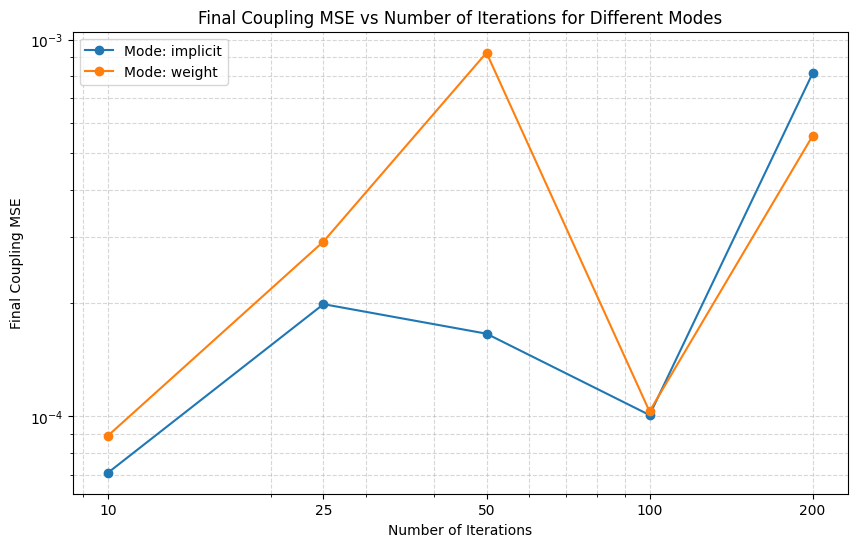

In [26]:
# Plot the results for final MSE in a single figure with 3 lines (one for each mode)plt.figure(figsize=(10, 6))
plt.figure(figsize=(10, 6))
for mode in ['implicit', 'weight']: # 'explicit',
    mses = []
    for n_iter in iteration_settings:
        try:
            key = f"{mode}_iter_{n_iter}"
            mse = results_antrot[key]['metrics']['coupling_errors']['mse'][-1]
            mses.append(mse)
        except:
            mses.append(0.0)
    plt.plot(iteration_settings, mses, marker='o', label=f'Mode: {mode}')
plt.xlabel('Number of Iterations')
plt.ylabel('Final Coupling MSE')
plt.title('Final Coupling MSE vs Number of Iterations for Different Modes')
plt.xscale('log')
plt.yscale('log')
plt.xticks(iteration_settings, iteration_settings)
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.savefig("coupling_mse_vs_iterations.png", dpi=250, bbox_inches="tight")
plt.show()

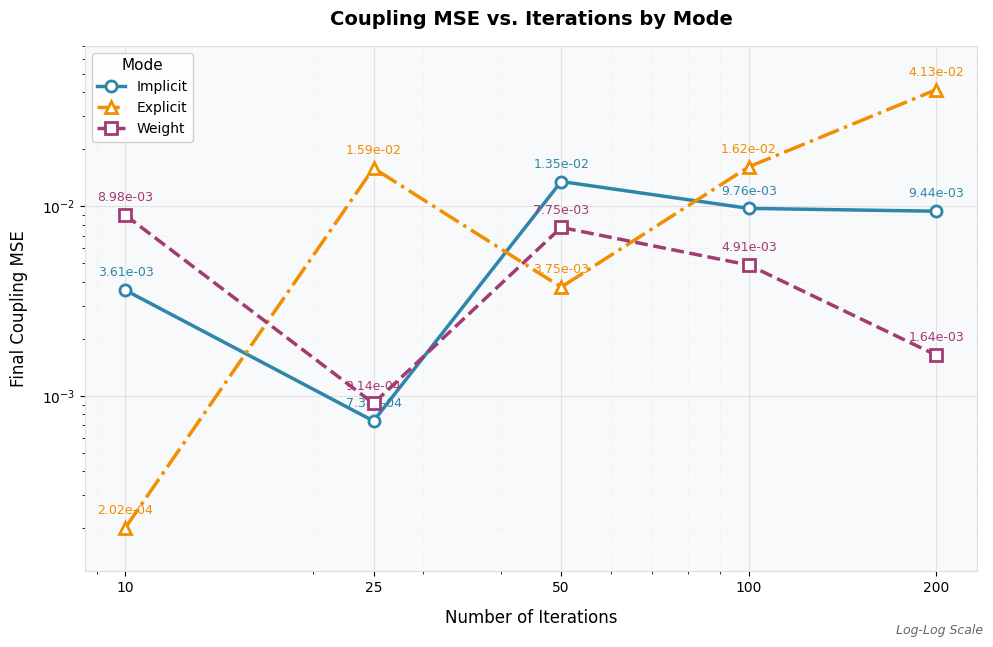

'\n# For publication style\nplt.style.use(\'seaborn-v0_8-whitegrid\')\nplt.figure(figsize=(8, 5))\n# ... (rest of plotting code with simpler styling)\nplt.savefig("coupling_mse_vs_iterations_paper.png", \n            dpi=600, \n            bbox_inches="tight")\nplt.show()\n'

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Define colors and styles
mode_colors = {
    'implicit': '#2E86AB',  # Professional blue
    'weight': '#A23B72',    # Elegant purple
    'explicit': '#F18F01'   # Warm orange (if you uncomment explicit later)
}

mode_line_styles = {
    'implicit': '-',
    'weight': '--',
    'explicit': '-.'
}

markers = {
    'implicit': 'o',
    'weight': 's',
    'explicit': '^'
}

# Create figure with better proportions
plt.figure(figsize=(10, 6.5), dpi=100)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titleweight'] = 'bold'

# Plot data
for mode in ['implicit', 'explicit', 'weight']:  # Add 'explicit' if needed
    mses = []
    valid_indices = []
    valid_iterations = []
    
    for i, n_iter in enumerate(iteration_settings):
        try:
            key = f"{mode}_iter_{n_iter}"
            mse = results_farantrot[key]['metrics']['coupling_errors']['mse'][-1]
            mses.append(mse)
            valid_indices.append(i)
            valid_iterations.append(n_iter)
        except:
            continue
    
    if mses:  # Only plot if we have data
        plt.plot(
            valid_iterations, 
            mses, 
            color=mode_colors.get(mode, '#333333'),
            linestyle=mode_line_styles.get(mode, '-'),
            linewidth=2.5,
            marker=markers.get(mode, 'o'),
            markersize=8,
            markerfacecolor='white',
            markeredgewidth=2,
            markeredgecolor=mode_colors.get(mode, '#333333'),
            label=mode.capitalize(),
            zorder=3
        )
        
        # Add data labels for key points
        if len(valid_iterations) <= 5:  # Label all points if few
            for x, y in zip(valid_iterations, mses):
                plt.annotate(
                    f'{y:.2e}',
                    xy=(x, y),
                    xytext=(0, 10),
                    textcoords='offset points',
                    ha='center',
                    fontsize=9,
                    color=mode_colors.get(mode, '#333333')
                )

# Customize axes
plt.xlabel('Number of Iterations', fontsize=12, fontweight='medium', labelpad=10)
plt.ylabel('Final Coupling MSE', fontsize=12, fontweight='medium', labelpad=10)
plt.title('Coupling MSE vs. Iterations by Mode', 
          fontsize=14, fontweight='bold', pad=15)

# Set scales
plt.xscale('log')
plt.yscale('log')

# Customize ticks
plt.xticks(iteration_settings, 
           [str(x) for x in iteration_settings],
           fontsize=10)
plt.yticks(fontsize=10)

# Add grid
plt.grid(True, which='major', linestyle='-', alpha=0.3, linewidth=0.8)
plt.grid(True, which='minor', linestyle=':', alpha=0.2, linewidth=0.5)

# Customize legend
plt.legend(
    title='Mode',
    title_fontsize=11,
    fontsize=10,
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor='#CCCCCC',
    facecolor='white',
    loc='best'
)

# Add some padding around the plot
plt.margins(x=0.05, y=0.1)

# Add a subtle border
for spine in plt.gca().spines.values():
    spine.set_edgecolor('#DDDDDD')
    spine.set_linewidth(0.8)

# Add a light background
plt.gca().set_facecolor('#f8f9fa')

# Add a subtle watermark/text note if desired
plt.figtext(0.99, 0.01, 'Log-Log Scale', 
            ha='right', va='bottom', 
            fontsize=9, alpha=0.6,
            style='italic')

# Adjust layout
plt.tight_layout()

# Save with higher quality
plt.savefig("farantrot_coupling_mse_vs_iterations_off.png", 
            dpi=300, 
            bbox_inches="tight",
            facecolor='white',
            edgecolor='none')

plt.show()

# Optional: Create a more compact version for publications
# Uncomment if needed:
"""
# For publication style
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(8, 5))
# ... (rest of plotting code with simpler styling)
plt.savefig("coupling_mse_vs_iterations_paper.png", 
            dpi=600, 
            bbox_inches="tight")
plt.show()
"""

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from typing import Optional, Tuple
from scipy.stats import gaussian_kde
from scipy.interpolate import griddata


def plot_presentation(
    source_dist,
    target_dist,
    trajectories: torch.Tensor,
    xlim: Optional[Tuple[float, float]] = (-8, 8),
    ylim: Optional[Tuple[float, float]] = (-8, 8),
    title: str = "Flow Matching: Trajectory Evolution",
    n_traj_to_plot=150,
    filename: Optional[str] = None,
):
    """
    Presentation-ready visualization of 2D flow matching trajectories.
    Uses gradient alpha lines and distinct terminal markers.
    """
    sns.set_theme(style="white")
    # Enforce square figure to prevent geometric distortion
    fig, ax = plt.subplots(figsize=(12, 12), dpi=150)

    # 1. PREP DATA
    traj_np = trajectories.detach().cpu().numpy()
    src_samples = source_dist.sample(50000).detach().cpu().numpy()
    tgt_samples = target_dist.sample(50000).detach().cpu().numpy()

    # 2. SEPARATE KDEs (The Fix)
    res = 200
    x_range = np.linspace(xlim[0], xlim[1], res)
    y_range = np.linspace(ylim[0], ylim[1], res)
    xi, yi = np.meshgrid(x_range, y_range)
    grid_coords = np.vstack([xi.flatten(), yi.flatten()])

    # Compute density for source and target independently to preserve shapes
    kde_src = gaussian_kde(src_samples.T, bw_method=0.2)
    kde_tgt = gaussian_kde(tgt_samples.T, bw_method=0.2)

    zi_src = kde_src(grid_coords).reshape(xi.shape)
    zi_tgt = kde_tgt(grid_coords).reshape(xi.shape)

    # Mathematically sum the fields (The Mixture)
    zi = zi_src + zi_tgt

    # 3. PLOT CONTOUR
    cf = ax.contourf(xi, yi, zi, levels=100, cmap="viridis", zorder=0)

    # Enforce aspect ratio
    ax.set_aspect("equal", adjustable="box")

    # 4. FIELD LINES (STREAMPLOT)
    # mid_idx = traj_np.shape[0] // 2
    # pts = traj_np[mid_idx, :, :2]
    # vel = traj_np[mid_idx + 1, :, :2] - traj_np[mid_idx, :, :2]

    # ui = griddata(pts, vel[:, 0], (xi, yi), method="linear", fill_value=0)
    # vi = griddata(pts, vel[:, 1], (xi, yi), method="linear", fill_value=0)

    # print(ui, vi)

    # ax.streamplot(xi, yi, ui, vi, color=(1, 0, 0, 0.55), density=1.5, linewidth=0.8, zorder=1)

    # 5. TRAJECTORIES
    # n_plot = min(n_traj_to_plot, traj_np.shape[1])
    n_plot = traj_np.shape[1]
    segments = [traj_np[:, i, :2] for i in range(n_plot)]
    lc = LineCollection(segments, colors="white", alpha=0.25, linewidths=1.2, zorder=2)
    ax.add_collection(lc)

    # 6. NEON MARKERS
    ax.scatter(
        traj_np[0, :n_plot, 0],
        traj_np[0, :n_plot, 1],
        c="#F90000",
        s=30,
        edgecolors="white",
        linewidth=0.6,
        label="Source ($\mu$)",
        zorder=4,
    )
    ax.scatter(
        traj_np[-1, :n_plot, 0],
        traj_np[-1, :n_plot, 1],
        c="#00FFFF",
        s=30,
        edgecolors="black",
        linewidth=0.6,
        label="Target ($\nu$)",
        zorder=5,
    )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title("Transfer Learning of data-based EOT", fontsize=22, fontweight="bold", pad=20)

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.tight_layout()
    plt.show()

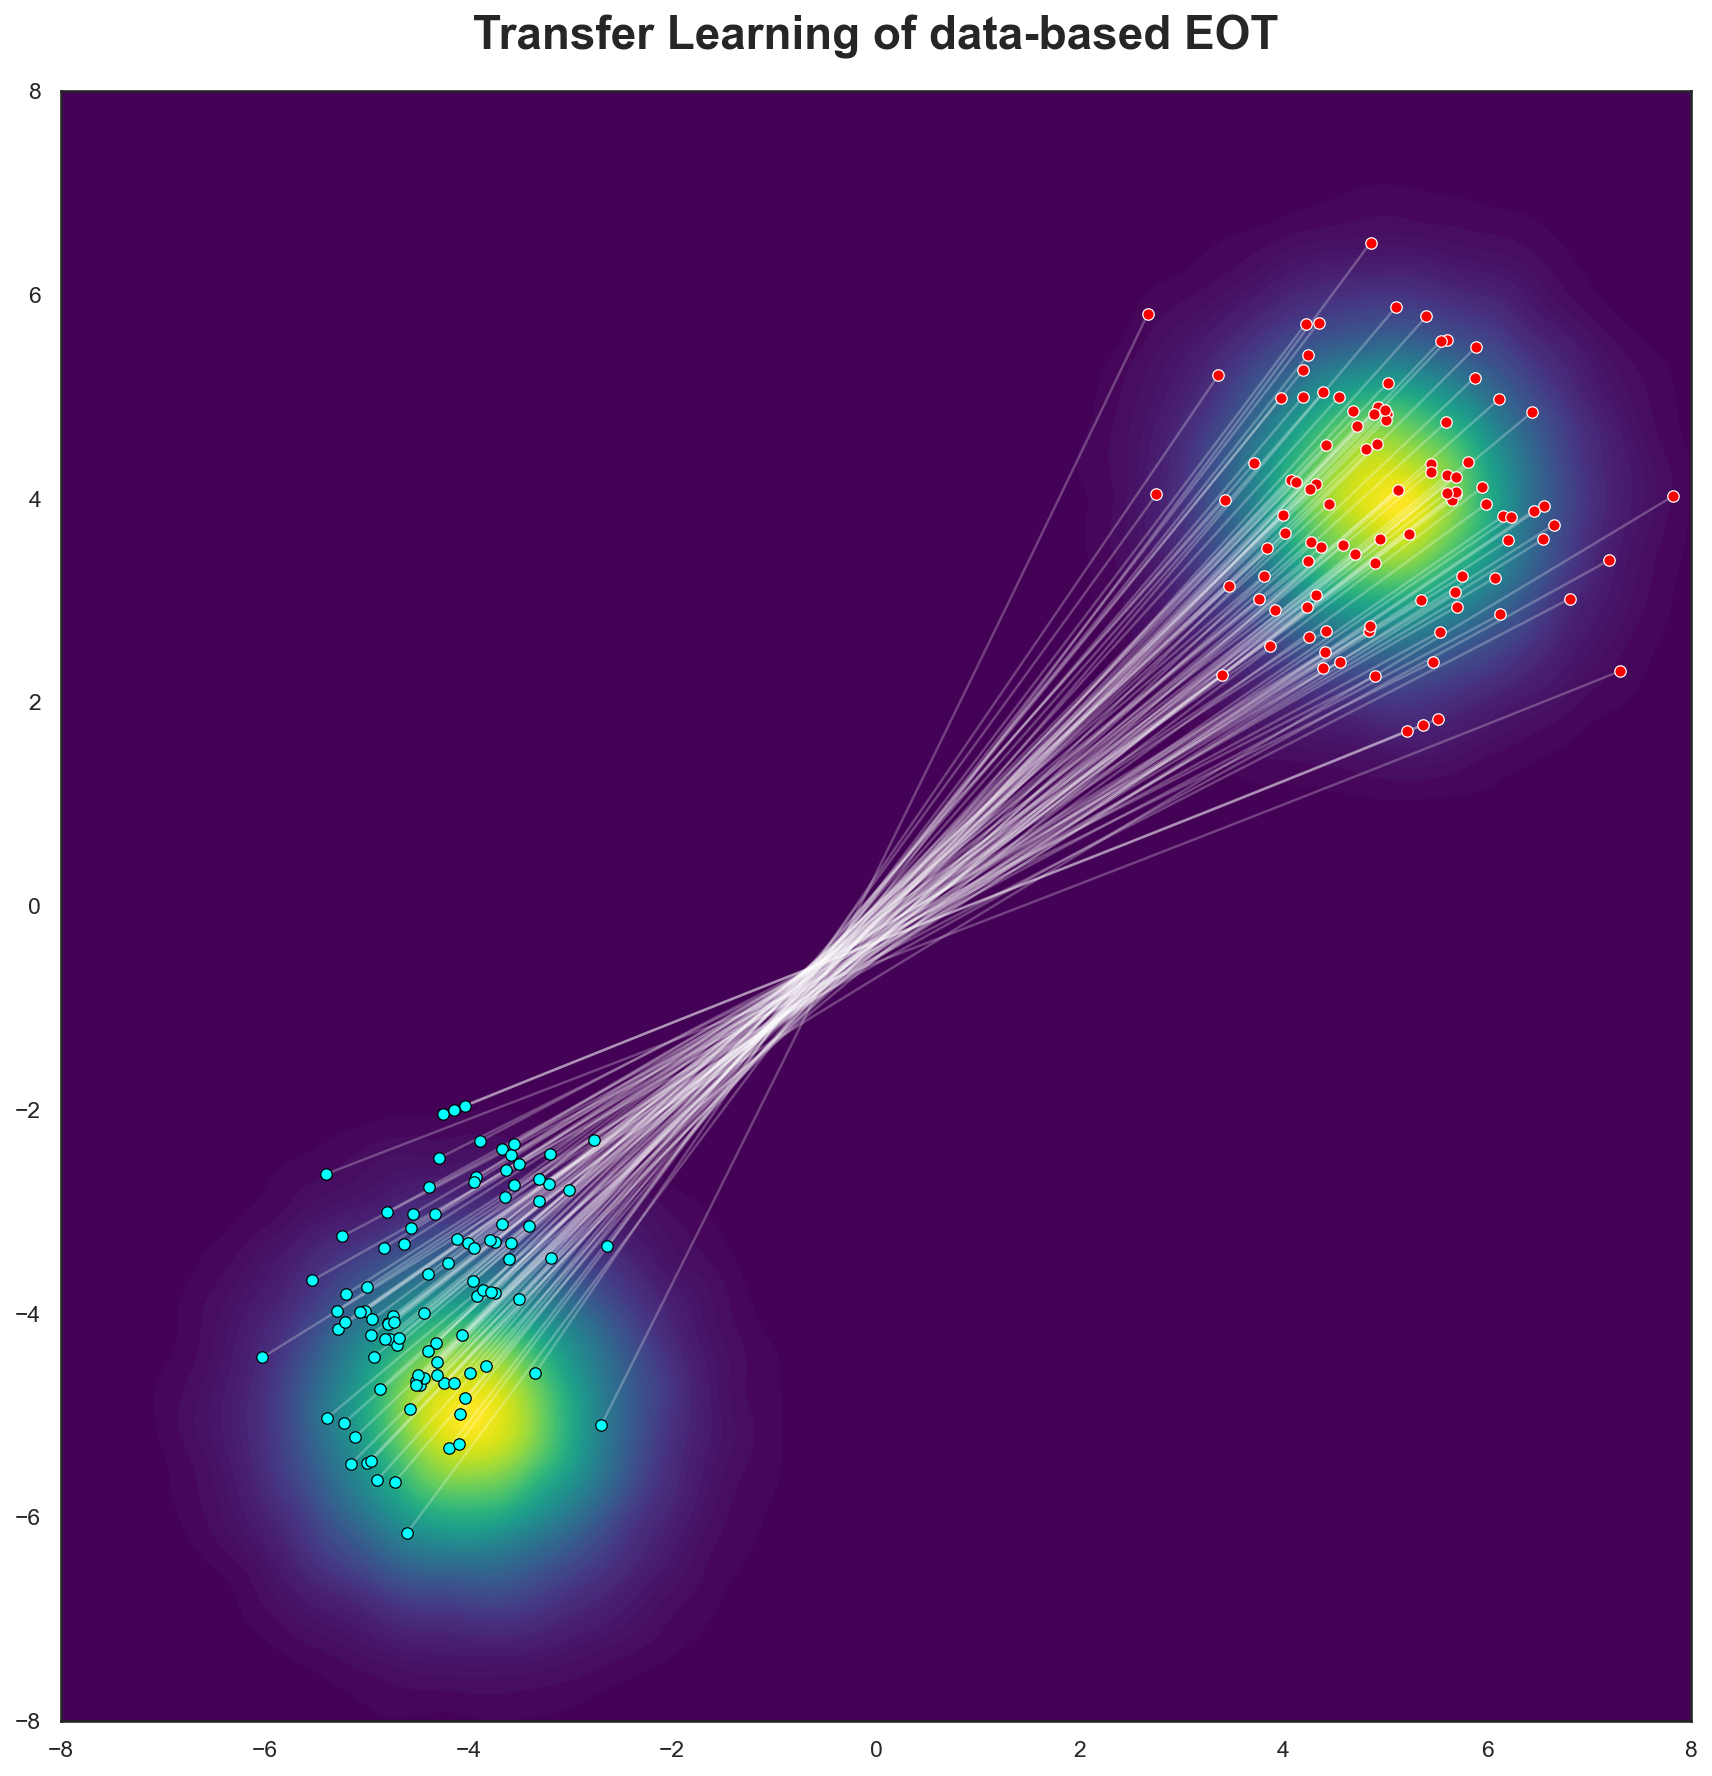

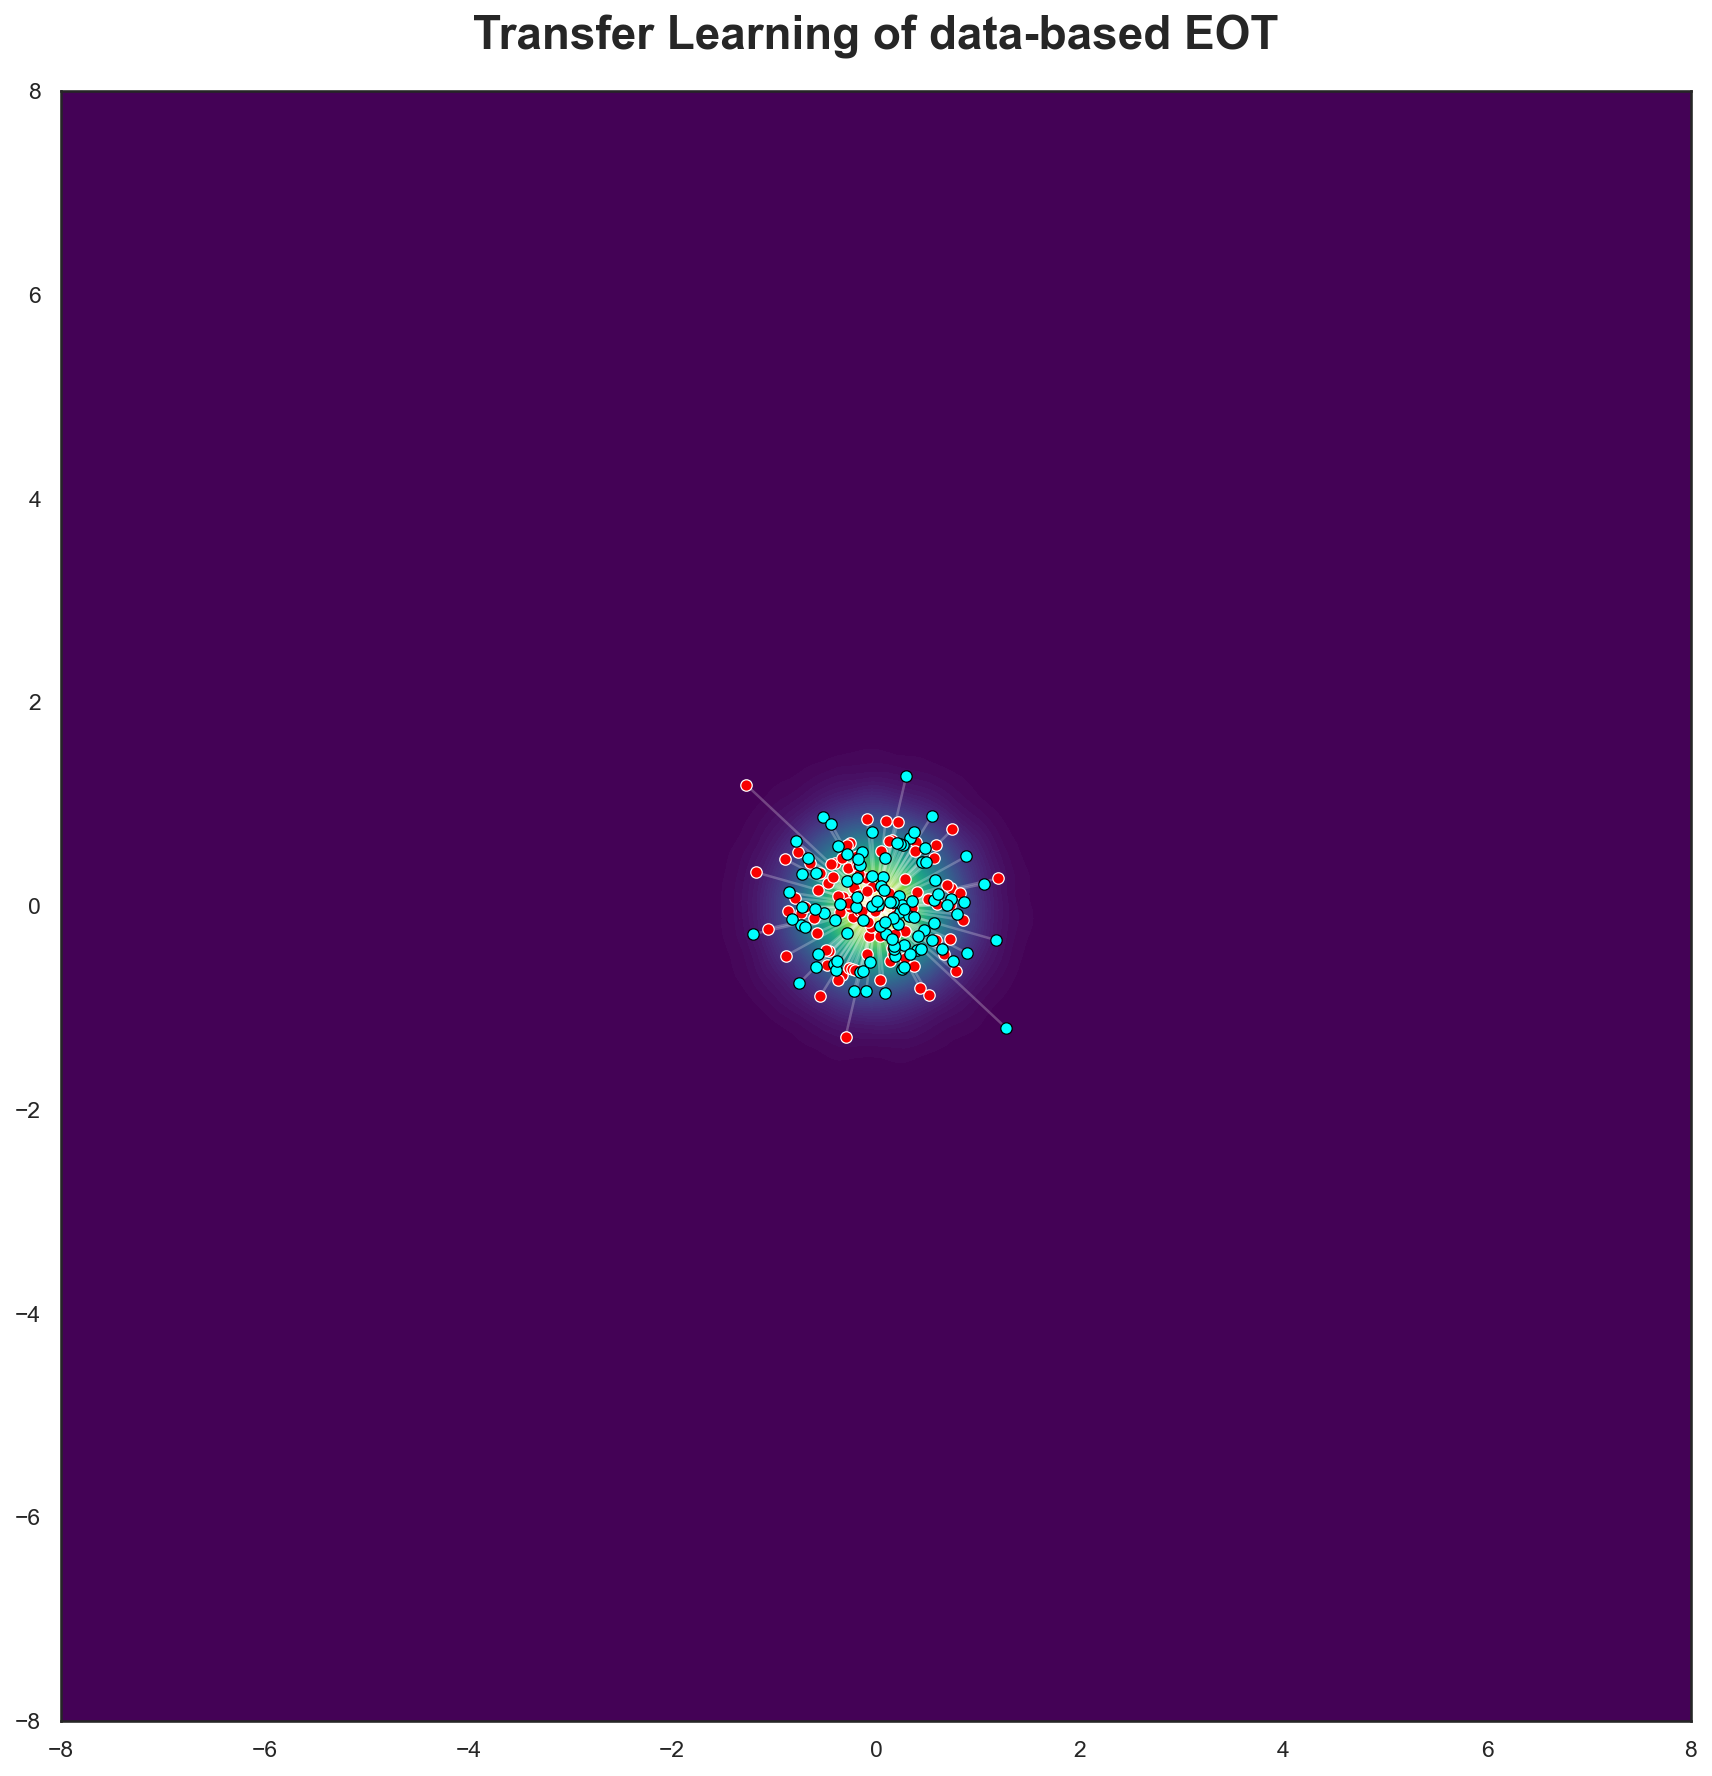

In [27]:
# experiment = load_experiment("experiments\\weight_iter_200_dual_100_cfm_250")
experiment = load_experiment("experiments\\gaussian_off_implicit_iter_200_dual_100_cfm_250")
distributions = create_distributions(device)
source_dist = distributions['new_source_dist']
target_dist = distributions['new_target_dist']
flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(device)
flow_model_mu.load_state_dict(experiment['checkpoint']['models']['flow_model_mu'])
cfm = ConditionalFlowMatching(source_dist, target_dist, flow_model_mu, sigma=0)
# cfm = ConditionalFlowMatching(source_dist, target_dist, initial_model_mu, sigma=0)

n_samples = 100
n_timesteps = 50
time = torch.linspace(0, 1, n_timesteps)
x_init = source_dist.sample(n_samples).to(device)
x_init = x_init.to(device)
x_init_extended = torch.cat([x_init, x_init], dim=1)
traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
target_samples = target_dist.sample(n_samples)

plot_presentation(
    source_dist=source_dist,
    target_dist=target_dist,
    trajectories=traj,
    xlim=(-8, 8),
    ylim=(-8, 8),
    title="W-CFM Trajectories after Final Step",
    filename="presentation_flow_matching_final.png"
)

experiment = load_experiment("experiments\\weight_iter_200_dual_100_cfm_250")
distributions = create_distributions(device)
source_dist = distributions['source_dist']
target_dist = distributions['target_dist']

n_samples = 100
n_timesteps = 50
time = torch.linspace(0, 1, n_timesteps)
x_init, y_init = distributions['coupling_dist'].coupling_sample(n_samples)
# Create dummy traj of shape [3, n_samples, :] with idx 1 as x_init + y_init /2
x_init_extended = torch.cat([x_init.to(device), x_init.to(device)], dim=1)
traj = torch.zeros((n_timesteps, n_samples, 4)).to(device)
traj[0] = x_init_extended
for t in range(1, n_timesteps):
    alpha = t / (n_timesteps - 1)
    traj[t, :, :2] = (1 - alpha) * x_init.to(device) + alpha * y_init.to(device)
    traj[t, :, 2:] = traj[t, :, :2]


plot_presentation(
    source_dist=source_dist,
    target_dist=target_dist,
    trajectories=traj,
    xlim=(-8, 8),
    ylim=(-8, 8),
    title="W-CFM Trajectories after Final Step",
    filename="presentation_flow_matching_initial.png"
)

In [ ]:
config = {
    "device": device,
    "batch_size": 2048,
    "epochs_marginal": 30000,
    "sigma": 0.1,
    "n_iterations": 10,
    "pretrained_epochs": 20000,
    "epochs_dual_per_step": 100,
    "epochs_cfm_per_step": 250,
    "dataset_size": 200_000,
    "mode": "implicit",
    "dual_lr": 1e-4,
    "cfm_lr": 5e-3,
    "gp_lambda": 0.1,
    "tau": 0.05,
}
name = f"test"
experiment = Experiment(name, config, coupling_fun=coupling_fun)
experiment.run(retrain=True)

In [152]:
# Save results_all for future analysis
import pickle
with open("results_rotation.pkl", "wb") as f:
    pickle.dump(results_rotation, f)